In [2]:
!pip install selenium

In [1]:
# ============================================================
# CARS24 WEB SCRAPING PROJECT
# Hyderabad Used Cars
# ============================================================

import requests
from bs4 import BeautifulSoup
import re
import numpy as np
import pandas as pd
import time

from selenium import webdriver
from selenium.webdriver.chrome.options import Options


# ============================================================
# 1. WEBSITE URL
# ============================================================

url = "https://www.cars24.com/buy-used-cars-hyderabad/"


# ============================================================
# 2. OPEN CHROME
# ============================================================

options = Options()
options.add_argument("--start-maximized")

driver = webdriver.Chrome(options=options)

driver.get(url)

time.sleep(7)


# ============================================================
# 3. EMPTY LISTS
# ============================================================

car_name = []
year = []
brand = []
model = []
variant = []
km_driven = []
fuel_type = []
transmission = []
registration = []
price = []
location = []


# ============================================================
# 4. SCRAPE AFTER EVERY SCROLL
# ============================================================

for scroll_no in range(20):

    print("\n====================================")
    print("SCROLL:", scroll_no + 1)
    print("====================================")


    # --------------------------------------------------------
    # GET CURRENT PAGE SOURCE
    # --------------------------------------------------------

    page = driver.page_source

    soup = BeautifulSoup(
        page,
        "html.parser"
    )


    # --------------------------------------------------------
    # CAR NAMES
    # --------------------------------------------------------

    car_name_data = soup.find_all(
        "span",
        class_="sc-bcXHqh bAcffq"
    )


    # --------------------------------------------------------
    # VARIANTS
    # --------------------------------------------------------

    variant_data = soup.find_all(
        "span",
        class_="sc-bcXHqh bKVBht"
    )


    # --------------------------------------------------------
    # VEHICLE DETAILS
    # --------------------------------------------------------

    vehicle_data = soup.find_all(
        "p",
        class_="sc-bcXHqh kNDBvu"
    )


    # --------------------------------------------------------
    # PRICE
    # --------------------------------------------------------

    price_texts = soup.find_all(
        string=re.compile(r"₹")
    )


    # --------------------------------------------------------
    # TEMPORARY LISTS FOR CURRENT BATCH
    # --------------------------------------------------------

    batch_car_name = []
    batch_year = []
    batch_brand = []
    batch_model = []
    batch_variant = []
    batch_km = []
    batch_fuel = []
    batch_transmission = []
    batch_registration = []
    batch_price = []


    # ========================================================
    # CAR NAME / YEAR / BRAND / MODEL
    # ========================================================

    for i in car_name_data:

        name = i.get_text(
            " ",
            strip=True
        )

        # Avoid duplicate cars
        if name in car_name:
            continue

        batch_car_name.append(name)


        # YEAR
        year_match = re.search(
            r"^(\d{4})",
            name
        )

        if year_match:

            batch_year.append(
                int(year_match.group(1))
            )

        else:

            batch_year.append(np.nan)


        # Remove year
        remaining_name = re.sub(
            r"^\d{4}\s*",
            "",
            name
        )

        words = remaining_name.split()


        # BRAND
        if len(words) >= 1:
            batch_brand.append(words[0])
        else:
            batch_brand.append(np.nan)


        # MODEL
        if len(words) >= 2:
            batch_model.append(words[1])
        else:
            batch_model.append(np.nan)


    # ========================================================
    # VARIANT
    # ========================================================

    for i in variant_data:

        value = i.get_text(
            " ",
            strip=True
        )

        if value:
            batch_variant.append(value)
        else:
            batch_variant.append(np.nan)


    # ========================================================
    # VEHICLE DETAILS
    # ========================================================

    for i in range(
        0,
        len(vehicle_data),
        4
    ):

        # KM
        if i < len(vehicle_data):

            value = vehicle_data[i].get_text(
                " ",
                strip=True
            )

            km_match = re.search(
                r"([\d,]+)\s*km",
                value,
                re.I
            )

            if km_match:
                batch_km.append(
                    km_match.group(1)
                )
            else:
                batch_km.append(np.nan)


        # FUEL
        if i + 1 < len(vehicle_data):

            value = vehicle_data[
                i + 1
            ].get_text(
                " ",
                strip=True
            )

            batch_fuel.append(value)


        # TRANSMISSION
        if i + 2 < len(vehicle_data):

            value = vehicle_data[
                i + 2
            ].get_text(
                " ",
                strip=True
            )

            batch_transmission.append(value)


        # REGISTRATION
        if i + 3 < len(vehicle_data):

            value = vehicle_data[
                i + 3
            ].get_text(
                " ",
                strip=True
            )

            batch_registration.append(value)


    # ========================================================
    # PRICE
    # ========================================================

    for i in price_texts:

        text = i.strip()

        match = re.search(
            r"₹\s*([\d.]+)\s*(lakh|L)",
            text,
            re.I
        )

        if match:

            value = (
                match.group(1)
                + " lakh"
            )

            batch_price.append(value)


    # Remove duplicate prices
    batch_price = list(
        dict.fromkeys(batch_price)
    )


    # ========================================================
    # MAKE CURRENT BATCH SAME LENGTH AS CARS
    # ========================================================

    n = len(batch_car_name)

    batch_year = batch_year[:n]
    batch_brand = batch_brand[:n]
    batch_model = batch_model[:n]
    batch_variant = batch_variant[:n]
    batch_km = batch_km[:n]
    batch_fuel = batch_fuel[:n]
    batch_transmission = batch_transmission[:n]
    batch_registration = batch_registration[:n]
    batch_price = batch_price[:n]


    # Fill missing values
    while len(batch_variant) < n:
        batch_variant.append(np.nan)

    while len(batch_km) < n:
        batch_km.append(np.nan)

    while len(batch_fuel) < n:
        batch_fuel.append(np.nan)

    while len(batch_transmission) < n:
        batch_transmission.append(np.nan)

    while len(batch_registration) < n:
        batch_registration.append(np.nan)

    while len(batch_price) < n:
        batch_price.append(np.nan)


    # ========================================================
    # APPEND CURRENT BATCH TO MAIN LISTS
    # ========================================================

    car_name.extend(batch_car_name)
    year.extend(batch_year)
    brand.extend(batch_brand)
    model.extend(batch_model)
    variant.extend(batch_variant)
    km_driven.extend(batch_km)
    fuel_type.extend(batch_fuel)
    transmission.extend(batch_transmission)
    registration.extend(batch_registration)
    price.extend(batch_price)


    print(
        "New Cars Added:",
        len(batch_car_name)
    )

    print(
        "Total Cars:",
        len(car_name)
    )


    # ========================================================
    # SCROLL DOWN
    # ========================================================

    driver.execute_script(
        "window.scrollBy(0, 1500);"
    )

    time.sleep(3)


# ============================================================
# 5. CREATE DATAFRAME
# ============================================================

data = pd.DataFrame({

    "Car Name": car_name,
    "Year": year,
    "Brand": brand,
    "Model": model,
    "Variant": variant,
    "KM Driven": km_driven,
    "Fuel Type": fuel_type,
    "Transmission": transmission,
    "Registration": registration,
    "Price": price

})


# ============================================================
# 6. REMOVE DUPLICATES
# ============================================================

data = data.drop_duplicates(
    subset=[
        "Car Name",
        "KM Driven"
    ]
).reset_index(drop=True)


# ============================================================
# 7. DISPLAY RESULT
# ============================================================

print("\n========================================")
print("SCRAPING COMPLETED")
print("========================================")

print(
    "Total Cars:",
    len(data)
)

print(
    "Shape:",
    data.shape
)

display(data.head(50))


# ============================================================
# 8. CLOSE BROWSER
# ============================================================

driver.quit()


SCROLL: 1
New Cars Added: 20
Total Cars: 20

SCROLL: 2
New Cars Added: 33
Total Cars: 53

SCROLL: 3
New Cars Added: 0
Total Cars: 53

SCROLL: 4
New Cars Added: 24
Total Cars: 77

SCROLL: 5
New Cars Added: 0
Total Cars: 77

SCROLL: 6
New Cars Added: 11
Total Cars: 88

SCROLL: 7
New Cars Added: 12
Total Cars: 100

SCROLL: 8
New Cars Added: 11
Total Cars: 111

SCROLL: 9
New Cars Added: 0
Total Cars: 111

SCROLL: 10
New Cars Added: 10
Total Cars: 121

SCROLL: 11
New Cars Added: 0
Total Cars: 121

SCROLL: 12
New Cars Added: 6
Total Cars: 127

SCROLL: 13
New Cars Added: 11
Total Cars: 138

SCROLL: 14
New Cars Added: 14
Total Cars: 152

SCROLL: 15
New Cars Added: 0
Total Cars: 152

SCROLL: 16
New Cars Added: 13
Total Cars: 165

SCROLL: 17
New Cars Added: 14
Total Cars: 179

SCROLL: 18
New Cars Added: 0
Total Cars: 179

SCROLL: 19
New Cars Added: 17
Total Cars: 196

SCROLL: 20
New Cars Added: 15
Total Cars: 211

SCRAPING COMPLETED
Total Cars: 211
Shape: (211, 10)


,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
0,2017 Maruti Baleno,2017.0,Maruti,Baleno,ALPHA PETROL 1.2,"48,349",Petrol,Manual,TS-28,1.33 lakh
1,2024 Maruti Swift,2024.0,Maruti,Swift,VXi (O),"15,400",Petrol,Manual,TG-11,3.50 lakh
2,2020 Renault Kwid,2020.0,Renault,Kwid,CLIMBER 1.0 (O),"33,425",Petrol,Manual,TS-15,0.63 lakh
3,2019 Maruti Swift,2019.0,Maruti,Swift,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
4,2022 Tata NEXON,2022.0,Tata,NEXON,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
5,2021 Renault Kwid,2021.0,Renault,Kwid,RXT 1.0 AMT (O),"43,964",Petrol,Auto,TS-08,6.00 lakh
6,2021 Tata NEXON,2021.0,Tata,NEXON,XM SUNROOF PETROL,"44,905",Petrol,Manual,AP-39,2.20 lakh
7,2020 Hyundai Elite i20,2020.0,Hyundai,Elite,ASTA 1.2 (O),"47,663",Petrol,Manual,TS-09,1.92 lakh
8,2020 KIA SELTOS,2020.0,KIA,SELTOS,HTK PLUS 1.5,"98,177",Petrol,Manual,TS-07,3.75 lakh
9,2022 Nissan MAGNITE,2022.0,Nissan,MAGNITE,XV PREMIUM TURBO CVT DUAL TONE,"42,756",Petrol,Auto,TS-09,6.45 lakh


In [2]:
data

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
0,2017 Maruti Baleno,2017.0,Maruti,Baleno,ALPHA PETROL 1.2,"48,349",Petrol,Manual,TS-28,1.33 lakh
1,2024 Maruti Swift,2024.0,Maruti,Swift,VXi (O),"15,400",Petrol,Manual,TG-11,3.50 lakh
2,2020 Renault Kwid,2020.0,Renault,Kwid,CLIMBER 1.0 (O),"33,425",Petrol,Manual,TS-15,0.63 lakh
3,2019 Maruti Swift,2019.0,Maruti,Swift,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
4,2022 Tata NEXON,2022.0,Tata,NEXON,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
...,...,...,...,...,...,...,...,...,...,...
206,2023 Maruti Alto,2023.0,Maruti,Alto,HTE 1.5D IMT,"46,427",Diesel,Manual,TS-04,4.70 lakh
207,2018 Tata Tiago,2018.0,Tata,Tiago,VX TECH QUADRAJET,"38,245",Diesel,Manual,AP-16,4.85 lakh
208,2017 Hyundai Verna,2017.0,Hyundai,Verna,SX PLUS 1.6 PETROL,"1,03,701",Petrol,Manual,TS-08,5.40 lakh
209,2016 Nissan Micra Active,2016.0,Nissan,Micra,DELTA PETROL 1.2,"59,345",Petrol,Manual,TS-08,10.95 lakh


In [4]:
data.to_csv("cars24_hyderabad_raw.csv",index=False)
print("Raw data saved successfully!")

Raw data saved successfully!


In [ ]:
# claning data

In [5]:
import numpy as np
import pandas as pd

In [6]:
data = pd.read_csv("cars24_hyderabad_raw.csv")

In [7]:
data

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
0,2017 Maruti Baleno,2017.0,Maruti,Baleno,ALPHA PETROL 1.2,"48,349",Petrol,Manual,TS-28,1.33 lakh
1,2024 Maruti Swift,2024.0,Maruti,Swift,VXi (O),"15,400",Petrol,Manual,TG-11,3.50 lakh
2,2020 Renault Kwid,2020.0,Renault,Kwid,CLIMBER 1.0 (O),"33,425",Petrol,Manual,TS-15,0.63 lakh
3,2019 Maruti Swift,2019.0,Maruti,Swift,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
4,2022 Tata NEXON,2022.0,Tata,NEXON,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
...,...,...,...,...,...,...,...,...,...,...
206,2023 Maruti Alto,2023.0,Maruti,Alto,HTE 1.5D IMT,"46,427",Diesel,Manual,TS-04,4.70 lakh
207,2018 Tata Tiago,2018.0,Tata,Tiago,VX TECH QUADRAJET,"38,245",Diesel,Manual,AP-16,4.85 lakh
208,2017 Hyundai Verna,2017.0,Hyundai,Verna,SX PLUS 1.6 PETROL,"1,03,701",Petrol,Manual,TS-08,5.40 lakh
209,2016 Nissan Micra Active,2016.0,Nissan,Micra,DELTA PETROL 1.2,"59,345",Petrol,Manual,TS-08,10.95 lakh


In [8]:
data.shape

(211, 10)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211 entries, 0 to 210
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car Name      211 non-null    object 
 1   Year          188 non-null    float64
 2   Brand         211 non-null    object 
 3   Model         198 non-null    object 
 4   Variant       211 non-null    object 
 5   KM Driven     211 non-null    object 
 6   Fuel Type     211 non-null    object 
 7   Transmission  211 non-null    object 
 8   Registration  211 non-null    object 
 9   Price         211 non-null    object 
dtypes: float64(1), object(9)
memory usage: 16.6+ KB


In [14]:
data.isnull().sum()

Car Name         0
Year            23
Brand            0
Model           13
Variant          0
KM Driven        0
Fuel Type        0
Transmission     0
Registration     0
Price            0
dtype: int64

In [13]:
data.duplicated().sum()

np.int64(0)

In [12]:
data[data["Model"].isnull()]

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
23,Maruti,NaN,Maruti,NaN,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
24,Hyundai,NaN,Hyundai,NaN,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
25,Tata,NaN,Tata,NaN,RXT 1.0 AMT (O),"43,964",Petrol,Auto,TS-08,6.00 lakh
26,Mahindra,NaN,Mahindra,NaN,XM SUNROOF PETROL,"44,905",Petrol,Manual,AP-39,2.20 lakh
27,Honda,NaN,Honda,NaN,ASTA 1.2 (O),"47,663",Petrol,Manual,TS-09,1.92 lakh
28,KIA,NaN,KIA,NaN,HTK PLUS 1.5,"98,177",Petrol,Manual,TS-07,3.75 lakh
29,MG,NaN,MG,NaN,XV PREMIUM TURBO CVT DUAL TONE,"42,756",Petrol,Auto,TS-09,6.45 lakh
30,Renault,NaN,Renault,NaN,HTE 1.5D IMT,"46,427",Diesel,Manual,TS-04,4.70 lakh
31,Volkswagen,NaN,Volkswagen,NaN,VX TECH QUADRAJET,"38,245",Diesel,Manual,AP-16,4.85 lakh
32,Ford,NaN,Ford,NaN,SX PLUS 1.6 PETROL,"1,03,701",Petrol,Manual,TS-08,5.40 lakh


In [16]:
data[data["Year"].isnull()]


,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
23,Maruti,NaN,Maruti,NaN,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
24,Hyundai,NaN,Hyundai,NaN,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
25,Tata,NaN,Tata,NaN,RXT 1.0 AMT (O),"43,964",Petrol,Auto,TS-08,6.00 lakh
26,Mahindra,NaN,Mahindra,NaN,XM SUNROOF PETROL,"44,905",Petrol,Manual,AP-39,2.20 lakh
27,Honda,NaN,Honda,NaN,ASTA 1.2 (O),"47,663",Petrol,Manual,TS-09,1.92 lakh
28,KIA,NaN,KIA,NaN,HTK PLUS 1.5,"98,177",Petrol,Manual,TS-07,3.75 lakh
29,MG,NaN,MG,NaN,XV PREMIUM TURBO CVT DUAL TONE,"42,756",Petrol,Auto,TS-09,6.45 lakh
30,Renault,NaN,Renault,NaN,HTE 1.5D IMT,"46,427",Diesel,Manual,TS-04,4.70 lakh
31,Volkswagen,NaN,Volkswagen,NaN,VX TECH QUADRAJET,"38,245",Diesel,Manual,AP-16,4.85 lakh
32,Ford,NaN,Ford,NaN,SX PLUS 1.6 PETROL,"1,03,701",Petrol,Manual,TS-08,5.40 lakh


In [17]:
data[data["Model"].isnull()]

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
23,Maruti,NaN,Maruti,NaN,VDI,"79,304",Diesel,Manual,TS-08,4.46 lakh
24,Hyundai,NaN,Hyundai,NaN,XM SUNROOF PETROL,"54,649",Petrol,Manual,TS-17,3.00 lakh
25,Tata,NaN,Tata,NaN,RXT 1.0 AMT (O),"43,964",Petrol,Auto,TS-08,6.00 lakh
26,Mahindra,NaN,Mahindra,NaN,XM SUNROOF PETROL,"44,905",Petrol,Manual,AP-39,2.20 lakh
27,Honda,NaN,Honda,NaN,ASTA 1.2 (O),"47,663",Petrol,Manual,TS-09,1.92 lakh
28,KIA,NaN,KIA,NaN,HTK PLUS 1.5,"98,177",Petrol,Manual,TS-07,3.75 lakh
29,MG,NaN,MG,NaN,XV PREMIUM TURBO CVT DUAL TONE,"42,756",Petrol,Auto,TS-09,6.45 lakh
30,Renault,NaN,Renault,NaN,HTE 1.5D IMT,"46,427",Diesel,Manual,TS-04,4.70 lakh
31,Volkswagen,NaN,Volkswagen,NaN,VX TECH QUADRAJET,"38,245",Diesel,Manual,AP-16,4.85 lakh
32,Ford,NaN,Ford,NaN,SX PLUS 1.6 PETROL,"1,03,701",Petrol,Manual,TS-08,5.40 lakh


In [18]:
data[data["Year"].isnull() | data["Model"].isnull()].shape

(23, 10)

In [20]:
data = data.dropna(
    subset=["Year", "Model"]
).reset_index(drop=True)

In [22]:
data.isnull().sum()

Car Name        0
Year            0
Brand           0
Model           0
Variant         0
KM Driven       0
Fuel Type       0
Transmission    0
Registration    0
Price           0
dtype: int64

In [25]:
data.dtypes

Car Name        object
Year             int64
Brand           object
Model           object
Variant         object
KM Driven       object
Fuel Type       object
Transmission    object
Registration    object
Price           object
dtype: object

In [24]:
data["Year"] = data["Year"].astype(int)

In [26]:
data["KM Driven"] = (
    data["KM Driven"]
    .str.replace(",", "", regex=False)
    .astype(int)
)

In [27]:
data["Price"] = (
    data["Price"]
    .str.replace(" lakh", "", regex=False)
    .astype(float)
    * 100000
)

In [28]:
data.dtypes

Car Name         object
Year              int64
Brand            object
Model            object
Variant          object
KM Driven         int64
Fuel Type        object
Transmission     object
Registration     object
Price           float64
dtype: object

In [29]:
data.head()

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
0,2017 Maruti Baleno,2017,Maruti,Baleno,ALPHA PETROL 1.2,48349,Petrol,Manual,TS-28,133000.0
1,2024 Maruti Swift,2024,Maruti,Swift,VXi (O),15400,Petrol,Manual,TG-11,350000.0
2,2020 Renault Kwid,2020,Renault,Kwid,CLIMBER 1.0 (O),33425,Petrol,Manual,TS-15,63000.0
3,2019 Maruti Swift,2019,Maruti,Swift,VDI,79304,Diesel,Manual,TS-08,446000.0
4,2022 Tata NEXON,2022,Tata,NEXON,XM SUNROOF PETROL,54649,Petrol,Manual,TS-17,300000.0


In [30]:
data["Brand"].value_counts()

Brand
Maruti        49
Hyundai       31
Tata          15
Mahindra      15
Renault       12
Honda         10
Volkswagen     8
Toyota         7
Nissan         7
Ford           7
Datsun         6
MG             6
KIA            5
Skoda          3
Jeep           3
Fiat           2
Chevrolet      1
Landrover      1
Name: count, dtype: int64

In [31]:
data.shape

(188, 10)

In [32]:
data.describe()

,Year,KM Driven,Price
count,188.000000,188.000000,1.880000e+02
mean,2019.297872,53679.367021,4.049468e+05
std,3.069009,22384.523518,2.460274e+05
min,2013.000000,15400.000000,6.300000e+04
25%,2017.000000,43662.000000,2.200000e+05
50%,2020.000000,47663.000000,3.750000e+05
75%,2022.000000,61224.000000,5.400000e+05
max,2024.000000,129377.000000,1.095000e+06


In [33]:
data["Brand"].value_counts()

Brand
Maruti        49
Hyundai       31
Tata          15
Mahindra      15
Renault       12
Honda         10
Volkswagen     8
Toyota         7
Nissan         7
Ford           7
Datsun         6
MG             6
KIA            5
Skoda          3
Jeep           3
Fiat           2
Chevrolet      1
Landrover      1
Name: count, dtype: int64

In [34]:
# Data visualization

In [50]:
# Univariate Analysis

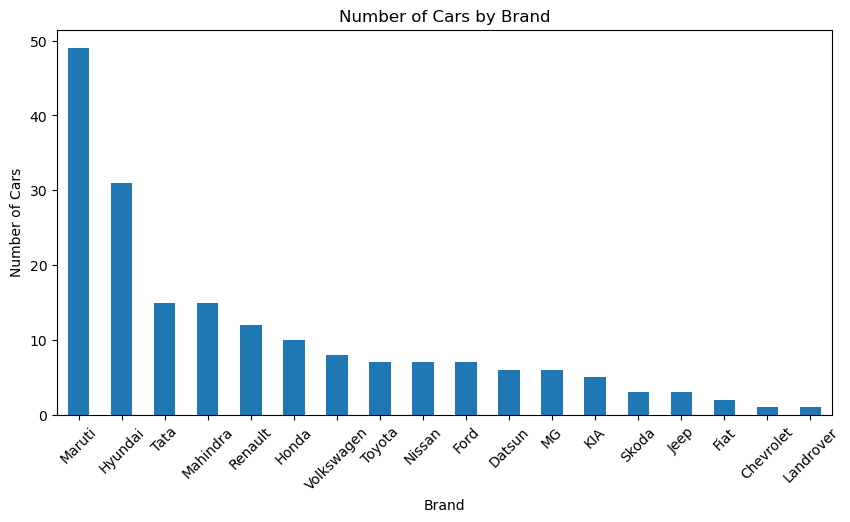

In [35]:
import matplotlib.pyplot as plt

data["Brand"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Number of Cars by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

In [36]:
data["Fuel Type"].value_counts()

Fuel Type
Petrol    154
Diesel     34
Name: count, dtype: int64

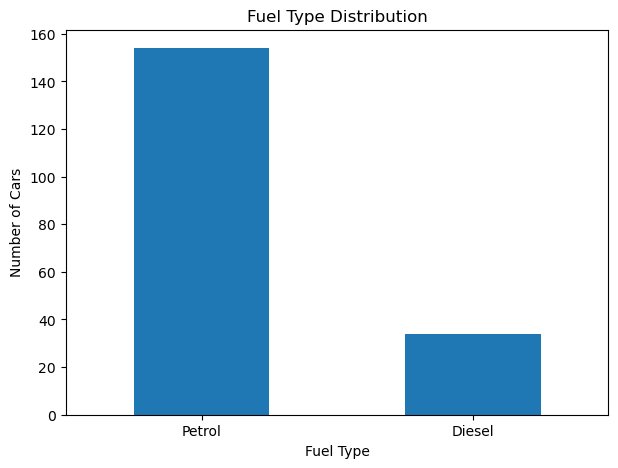

In [44]:
data["Fuel Type"].value_counts().plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Fuel Type Distribution")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)
plt.show()

In [41]:
data["Transmission"].value_counts()

Transmission
Manual    159
Auto       29
Name: count, dtype: int64

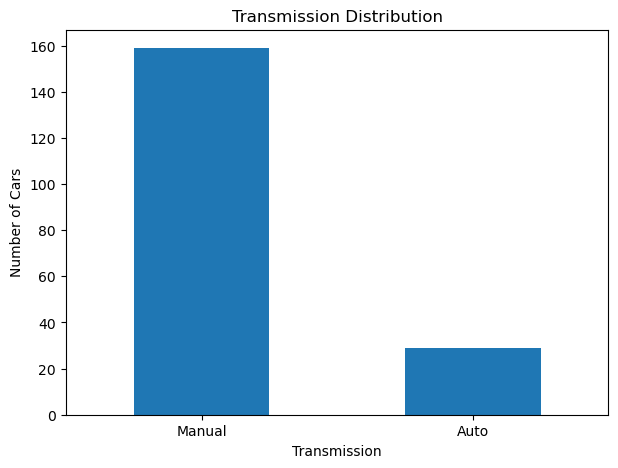

In [43]:
data["Transmission"].value_counts().plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Transmission Distribution")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)

plt.show()

In [49]:
# Numerical Analysis

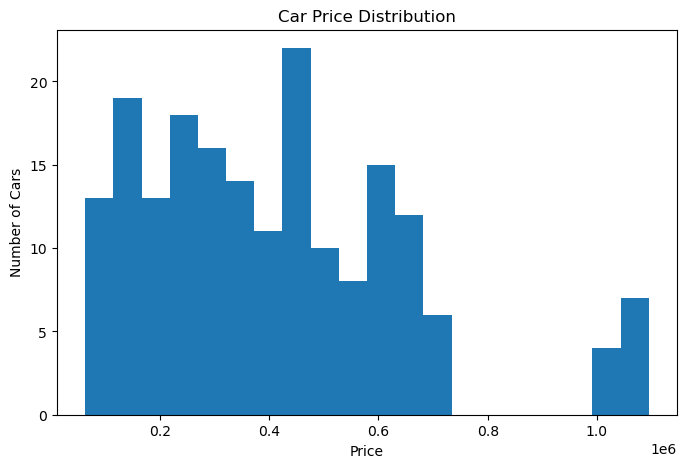

In [46]:
plt.figure(figsize=(8,5))
plt.hist(data["Price"], bins=20)
plt.title("Car Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

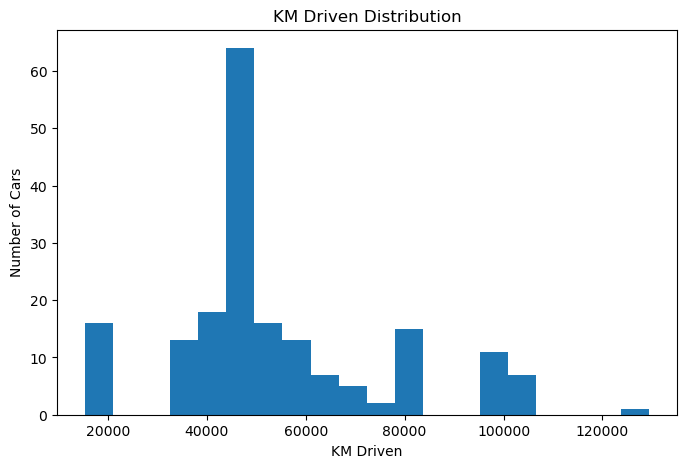

In [47]:
plt.figure(figsize=(8,5))

plt.hist(data["KM Driven"], bins=20)

plt.title("KM Driven Distribution")
plt.xlabel("KM Driven")
plt.ylabel("Number of Cars")

plt.show()

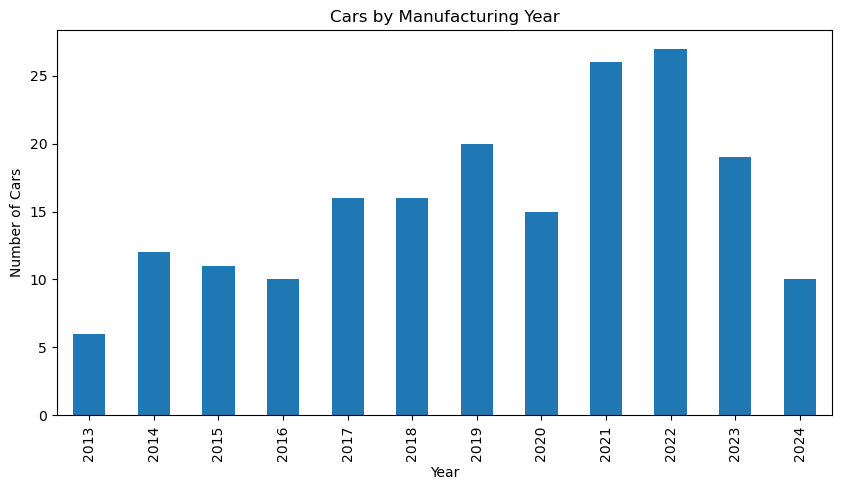

In [48]:
data["Year"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Cars by Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Number of Cars")

plt.show()

In [51]:
# Business Analysis

In [52]:
brand_price = data.groupby("Brand")["Price"].mean().sort_values(
    ascending=False
)

brand_price

Brand
Skoda         751000.000000
Chevrolet     730000.000000
Nissan        558000.000000
MG            500666.666667
Renault       490250.000000
Ford          469142.857143
Honda         440000.000000
Fiat          408500.000000
Maruti        408183.673469
Mahindra      403333.333333
Volkswagen    366000.000000
Tata          359866.666667
Hyundai       353774.193548
Toyota        341857.142857
Jeep          333000.000000
KIA           300800.000000
Datsun        243833.333333
Landrover     150000.000000
Name: Price, dtype: float64

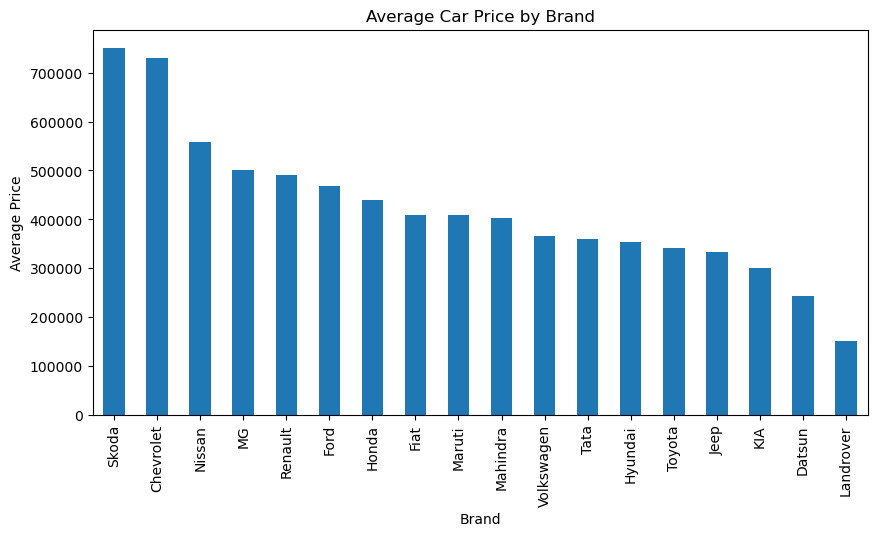

In [53]:
brand_price.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Average Car Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")

plt.show()

In [54]:
brand_km = data.groupby("Brand")["KM Driven"].mean().sort_values(
    ascending=False
)

brand_km

Brand
Jeep          84721.000000
Landrover     82103.000000
MG            61080.166667
Ford          61071.285714
KIA           59816.400000
Hyundai       58211.322581
Nissan        57029.571429
Volkswagen    55004.625000
Tata          52947.533333
Maruti        51076.408163
Skoda         50705.000000
Mahindra      50187.066667
Toyota        50090.285714
Fiat          49624.000000
Renault       48691.166667
Honda         46826.200000
Chevrolet     45924.000000
Datsun        44726.666667
Name: KM Driven, dtype: float64

In [55]:
fuel_price = data.groupby("Fuel Type")["Price"].mean()
fuel_price

Fuel Type
Diesel    453029.411765
Petrol    394331.168831
Name: Price, dtype: float64

In [56]:
trans_price = data.groupby("Transmission")["Price"].mean()
trans_price

Transmission
Auto      576241.379310
Manual    373704.402516
Name: Price, dtype: float64

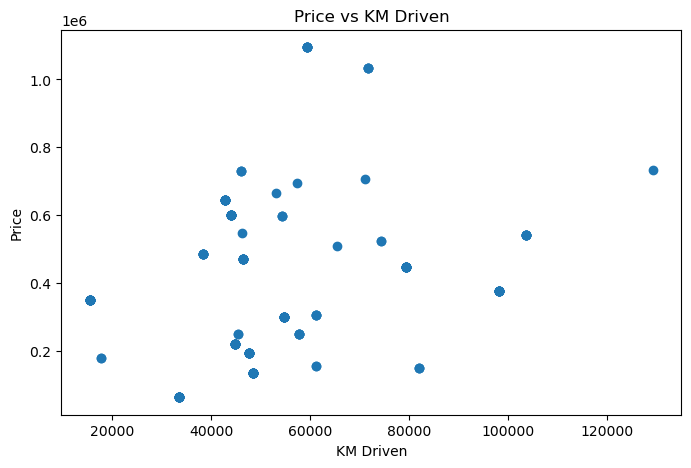

In [57]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["KM Driven"],
    data["Price"]
)

plt.title("Price vs KM Driven")
plt.xlabel("KM Driven")
plt.ylabel("Price")

plt.show()

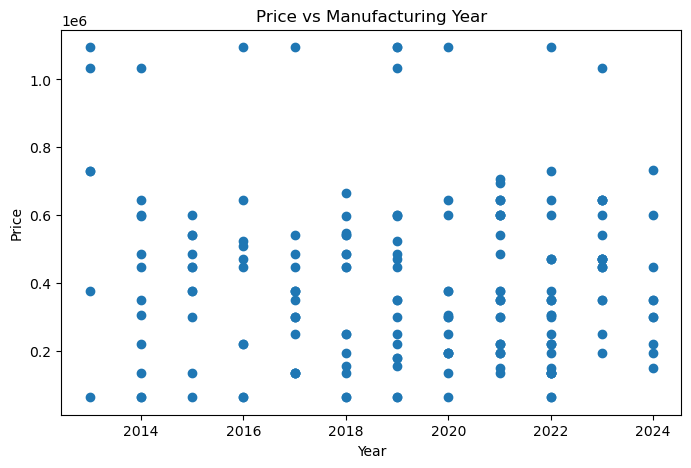

In [58]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["Year"],
    data["Price"]
)

plt.title("Price vs Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Price")

plt.show()

In [61]:
# outliers

In [59]:
Q1 = data["Price"].quantile(0.25)
Q3 = data["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -259999.99999999997
Upper Bound: 1020000.0


In [60]:
price_outliers = data[
    (data["Price"] < lower_bound) |
    (data["Price"] > upper_bound)
]

price_outliers

,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
13,2019 Maruti Baleno,2019,Maruti,Baleno,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
16,2014 Volkswagen Polo,2014,Volkswagen,Polo,HIGHLINE1.2L,71784,Petrol,Manual,TS-09,1033000.0
23,2022 Skoda SLAVIA,2022,Skoda,SLAVIA,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
26,2019 MG HECTOR,2019,MG,HECTOR,HIGHLINE1.2L,71784,Petrol,Manual,TS-09,1033000.0
43,2013 Skoda Rapid,2013,Skoda,Rapid,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
46,2023 Renault TRIBER,2023,Renault,TRIBER,HIGHLINE1.2L,71784,Petrol,Manual,TS-09,1033000.0
128,2019 Maruti Alto 800,2019,Maruti,Alto,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
155,2020 Honda Amaze,2020,Honda,Amaze,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
169,2017 Ford Figo Aspire,2017,Ford,Figo,DELTA PETROL 1.2,59345,Petrol,Manual,TS-08,1095000.0
172,2013 Maruti A Star,2013,Maruti,A,HIGHLINE1.2L,71784,Petrol,Manual,TS-09,1033000.0


In [62]:
Q1_km = data["KM Driven"].quantile(0.25)
Q3_km = data["KM Driven"].quantile(0.75)

IQR_km = Q3_km - Q1_km

lower_bound_km = Q1_km - 1.5 * IQR_km
upper_bound_km = Q3_km + 1.5 * IQR_km

print("Lower Bound:", lower_bound_km)
print("Upper Bound:", upper_bound_km)

Lower Bound: 17319.0
Upper Bound: 87567.0


In [64]:
km_outliers = data[
    (data["KM Driven"] < lower_bound_km) |
    (data["KM Driven"] > upper_bound_km)
]

km_outliers


,Car Name,Year,Brand,Model,Variant,KM Driven,Fuel Type,Transmission,Registration,Price
1,2024 Maruti Swift,2024,Maruti,Swift,VXi (O),15400,Petrol,Manual,TG-11,350000.0
8,2020 KIA SELTOS,2020,KIA,SELTOS,HTK PLUS 1.5,98177,Petrol,Manual,TS-07,375000.0
12,2018 Hyundai Creta,2018,Hyundai,Creta,SX PLUS 1.6 PETROL,103701,Petrol,Manual,TS-08,540000.0
21,2019 Datsun Redi Go,2019,Datsun,Redi,VXi (O),15400,Petrol,Manual,TG-11,350000.0
36,2024 Nissan MAGNITE,2024,Nissan,MAGNITE,SHARP 2.0 DIESEL,129377,Diesel,Manual,TS-19,732000.0
41,2021 Mahindra XUV700,2021,Mahindra,XUV700,VXi (O),15400,Petrol,Manual,TG-11,350000.0
42,2015 Maruti Wagon R 1.0,2015,Maruti,Wagon,SX PLUS 1.6 PETROL,103701,Petrol,Manual,TS-08,540000.0
55,2019 Honda Amaze,2019,Honda,Amaze,VXi (O),15400,Petrol,Manual,TG-11,350000.0
62,2017 Jeep Compass,2017,Jeep,Compass,HTK PLUS 1.5,98177,Petrol,Manual,TS-07,375000.0
66,2021 Mahindra BOLERO NEO,2021,Mahindra,BOLERO,VXi (O),15400,Petrol,Manual,TG-11,350000.0


In [65]:
print("Number of KM Outliers:", len(km_outliers))

Number of KM Outliers: 33


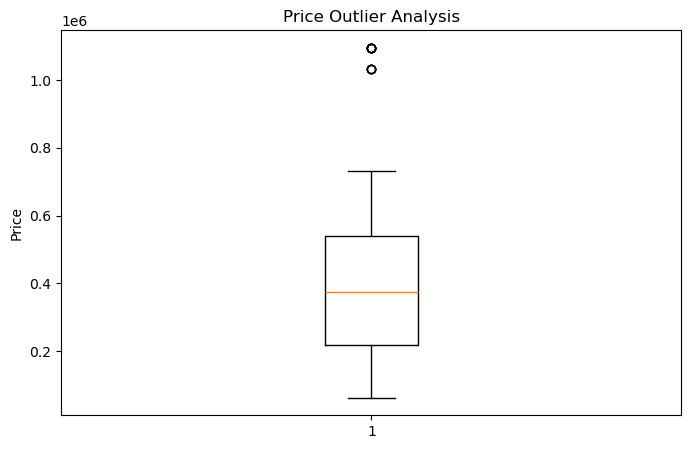

In [66]:
plt.figure(figsize=(8,5))

plt.boxplot(data["Price"])

plt.title("Price Outlier Analysis")
plt.ylabel("Price")

plt.show()

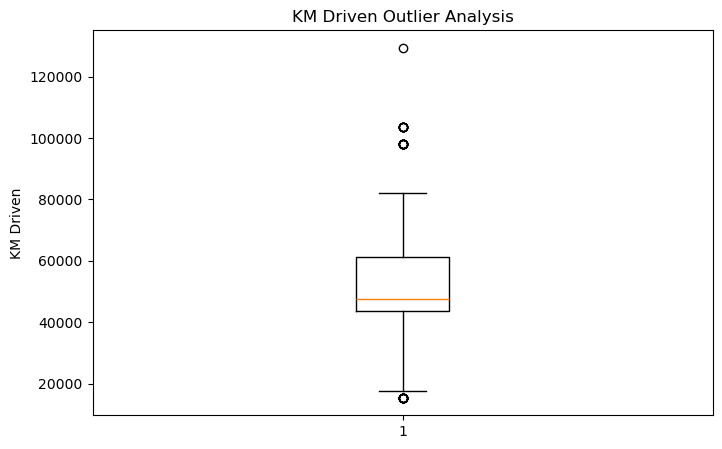

In [67]:
plt.figure(figsize=(8,5))

plt.boxplot(data["KM Driven"])

plt.title("KM Driven Outlier Analysis")
plt.ylabel("KM Driven")

plt.show()

In [68]:
correlation = data[
    ["Year", "KM Driven", "Price"]
].corr()

correlation

,Year,KM Driven,Price
Year,1.000000,-0.110988,-0.064768
KM Driven,-0.110988,1.000000,0.232534
Price,-0.064768,0.232534,1.000000


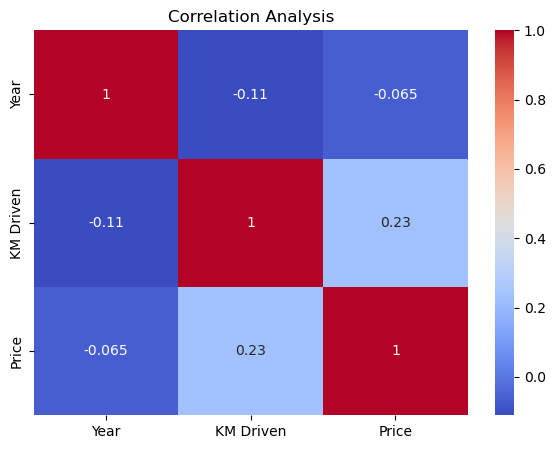

In [69]:
import seaborn as sns

plt.figure(figsize=(7,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Analysis")

plt.show()

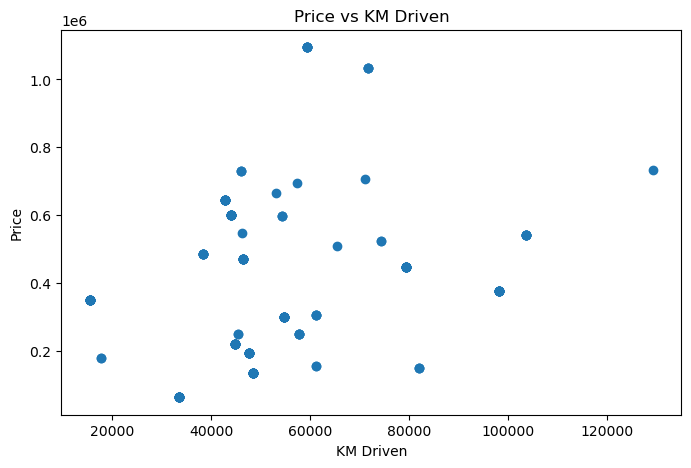

In [70]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["KM Driven"],
    data["Price"]
)

plt.title("Price vs KM Driven")
plt.xlabel("KM Driven")
plt.ylabel("Price")

plt.show()

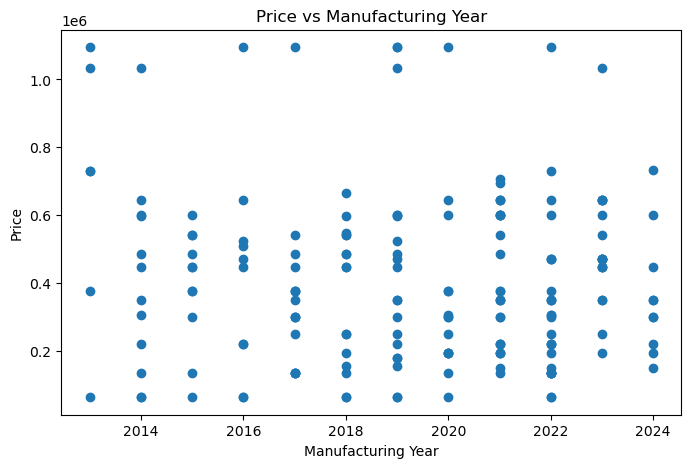

In [71]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["Year"],
    data["Price"]
)

plt.title("Price vs Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price")

plt.show()

In [72]:
brand_avg_price = (
    data.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
)

brand_avg_price

Brand
Skoda         751000.000000
Chevrolet     730000.000000
Nissan        558000.000000
MG            500666.666667
Renault       490250.000000
Ford          469142.857143
Honda         440000.000000
Fiat          408500.000000
Maruti        408183.673469
Mahindra      403333.333333
Volkswagen    366000.000000
Tata          359866.666667
Hyundai       353774.193548
Toyota        341857.142857
Jeep          333000.000000
KIA           300800.000000
Datsun        243833.333333
Landrover     150000.000000
Name: Price, dtype: float64

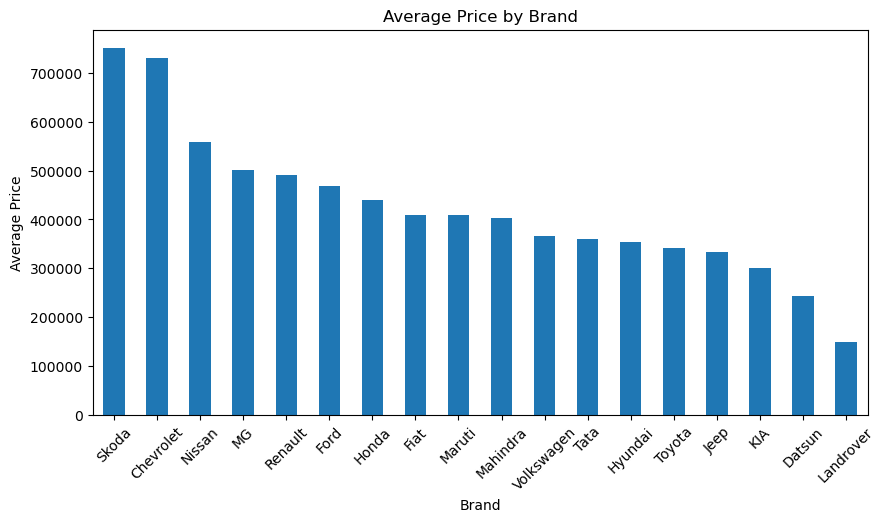

In [73]:
brand_avg_price.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Average Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")

plt.xticks(rotation=45)

plt.show()

In [74]:
brand_avg_km = (
    data.groupby("Brand")["KM Driven"]
    .mean()
    .sort_values(ascending=False)
)

brand_avg_km

Brand
Jeep          84721.000000
Landrover     82103.000000
MG            61080.166667
Ford          61071.285714
KIA           59816.400000
Hyundai       58211.322581
Nissan        57029.571429
Volkswagen    55004.625000
Tata          52947.533333
Maruti        51076.408163
Skoda         50705.000000
Mahindra      50187.066667
Toyota        50090.285714
Fiat          49624.000000
Renault       48691.166667
Honda         46826.200000
Chevrolet     45924.000000
Datsun        44726.666667
Name: KM Driven, dtype: float64

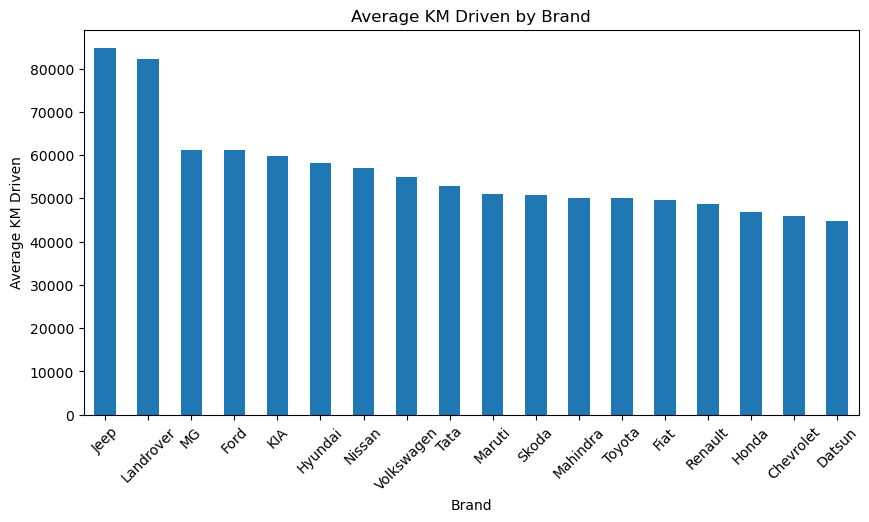

In [75]:
brand_avg_km.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Average KM Driven by Brand")
plt.xlabel("Brand")
plt.ylabel("Average KM Driven")

plt.xticks(rotation=45)

plt.show()

In [76]:
fuel_avg_price = (
    data.groupby("Fuel Type")["Price"]
    .mean()
    .sort_values(ascending=False)
)

fuel_avg_price

Fuel Type
Diesel    453029.411765
Petrol    394331.168831
Name: Price, dtype: float64

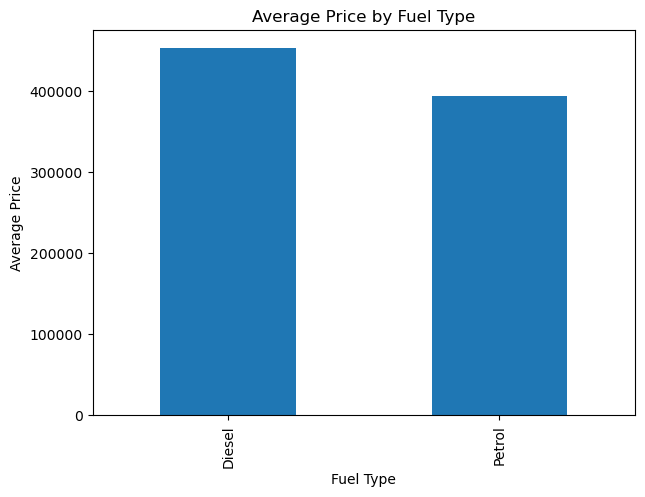

In [77]:
fuel_avg_price.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Average Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price")

plt.show()

In [78]:
transmission_avg_price = (
    data.groupby("Transmission")["Price"]
    .mean()
    .sort_values(ascending=False)
)

transmission_avg_price

Transmission
Auto      576241.379310
Manual    373704.402516
Name: Price, dtype: float64

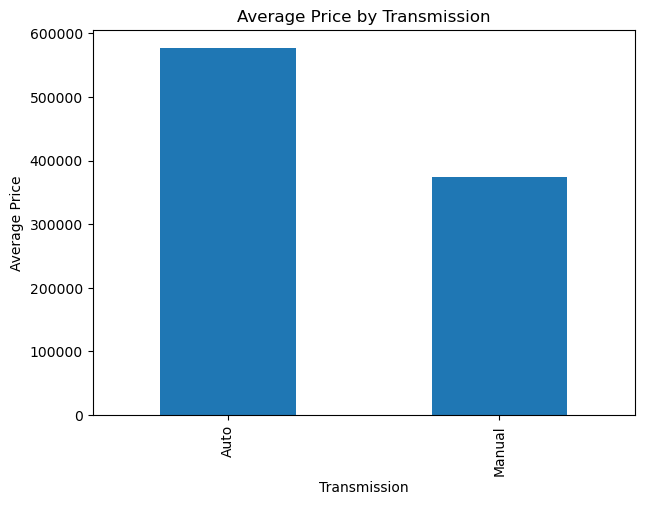

In [79]:
transmission_avg_price.plot(
    kind="bar",
    figsize=(7,5)
)
plt.title("Average Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Average Price")

plt.show()

In [80]:
year_count = data["Year"].value_counts().sort_index()

year_count

Year
2013     6
2014    12
2015    11
2016    10
2017    16
2018    16
2019    20
2020    15
2021    26
2022    27
2023    19
2024    10
Name: count, dtype: int64

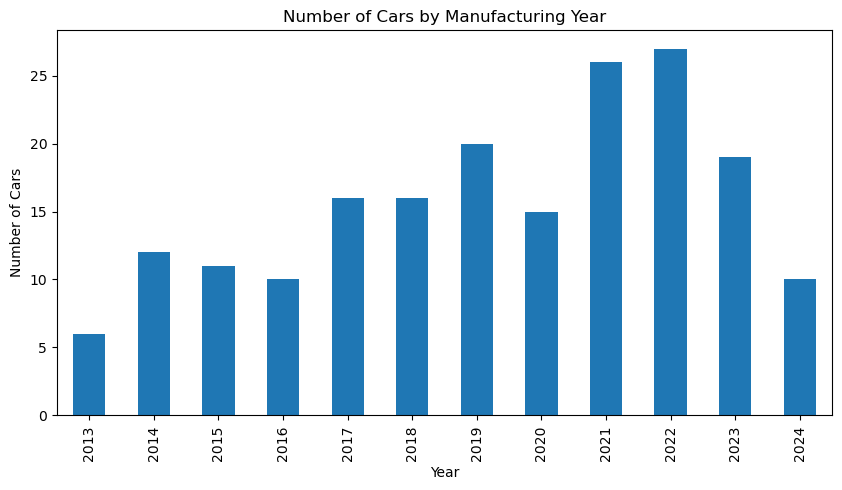

In [81]:
year_count.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Number of Cars by Manufacturing Year")
plt.xlabel("Year")
plt.ylabel("Number of Cars")

plt.show()

In [82]:
data.to_csv("cars24_hyderabad_final.csv", index=False)